Autor: Estéfano Galarza

Tema tesis: Predicción temprana de estres usando datos fisiológicos multimodales

Proyecto: Prediccion sobre actividad usando datos fisiológicos. Introduccion/motivacion, EDA, Feature Extraction, Feature Selection, Optimización de hiperparametros, Comparación estadística de técnicas ML (Random Forest, transformers)

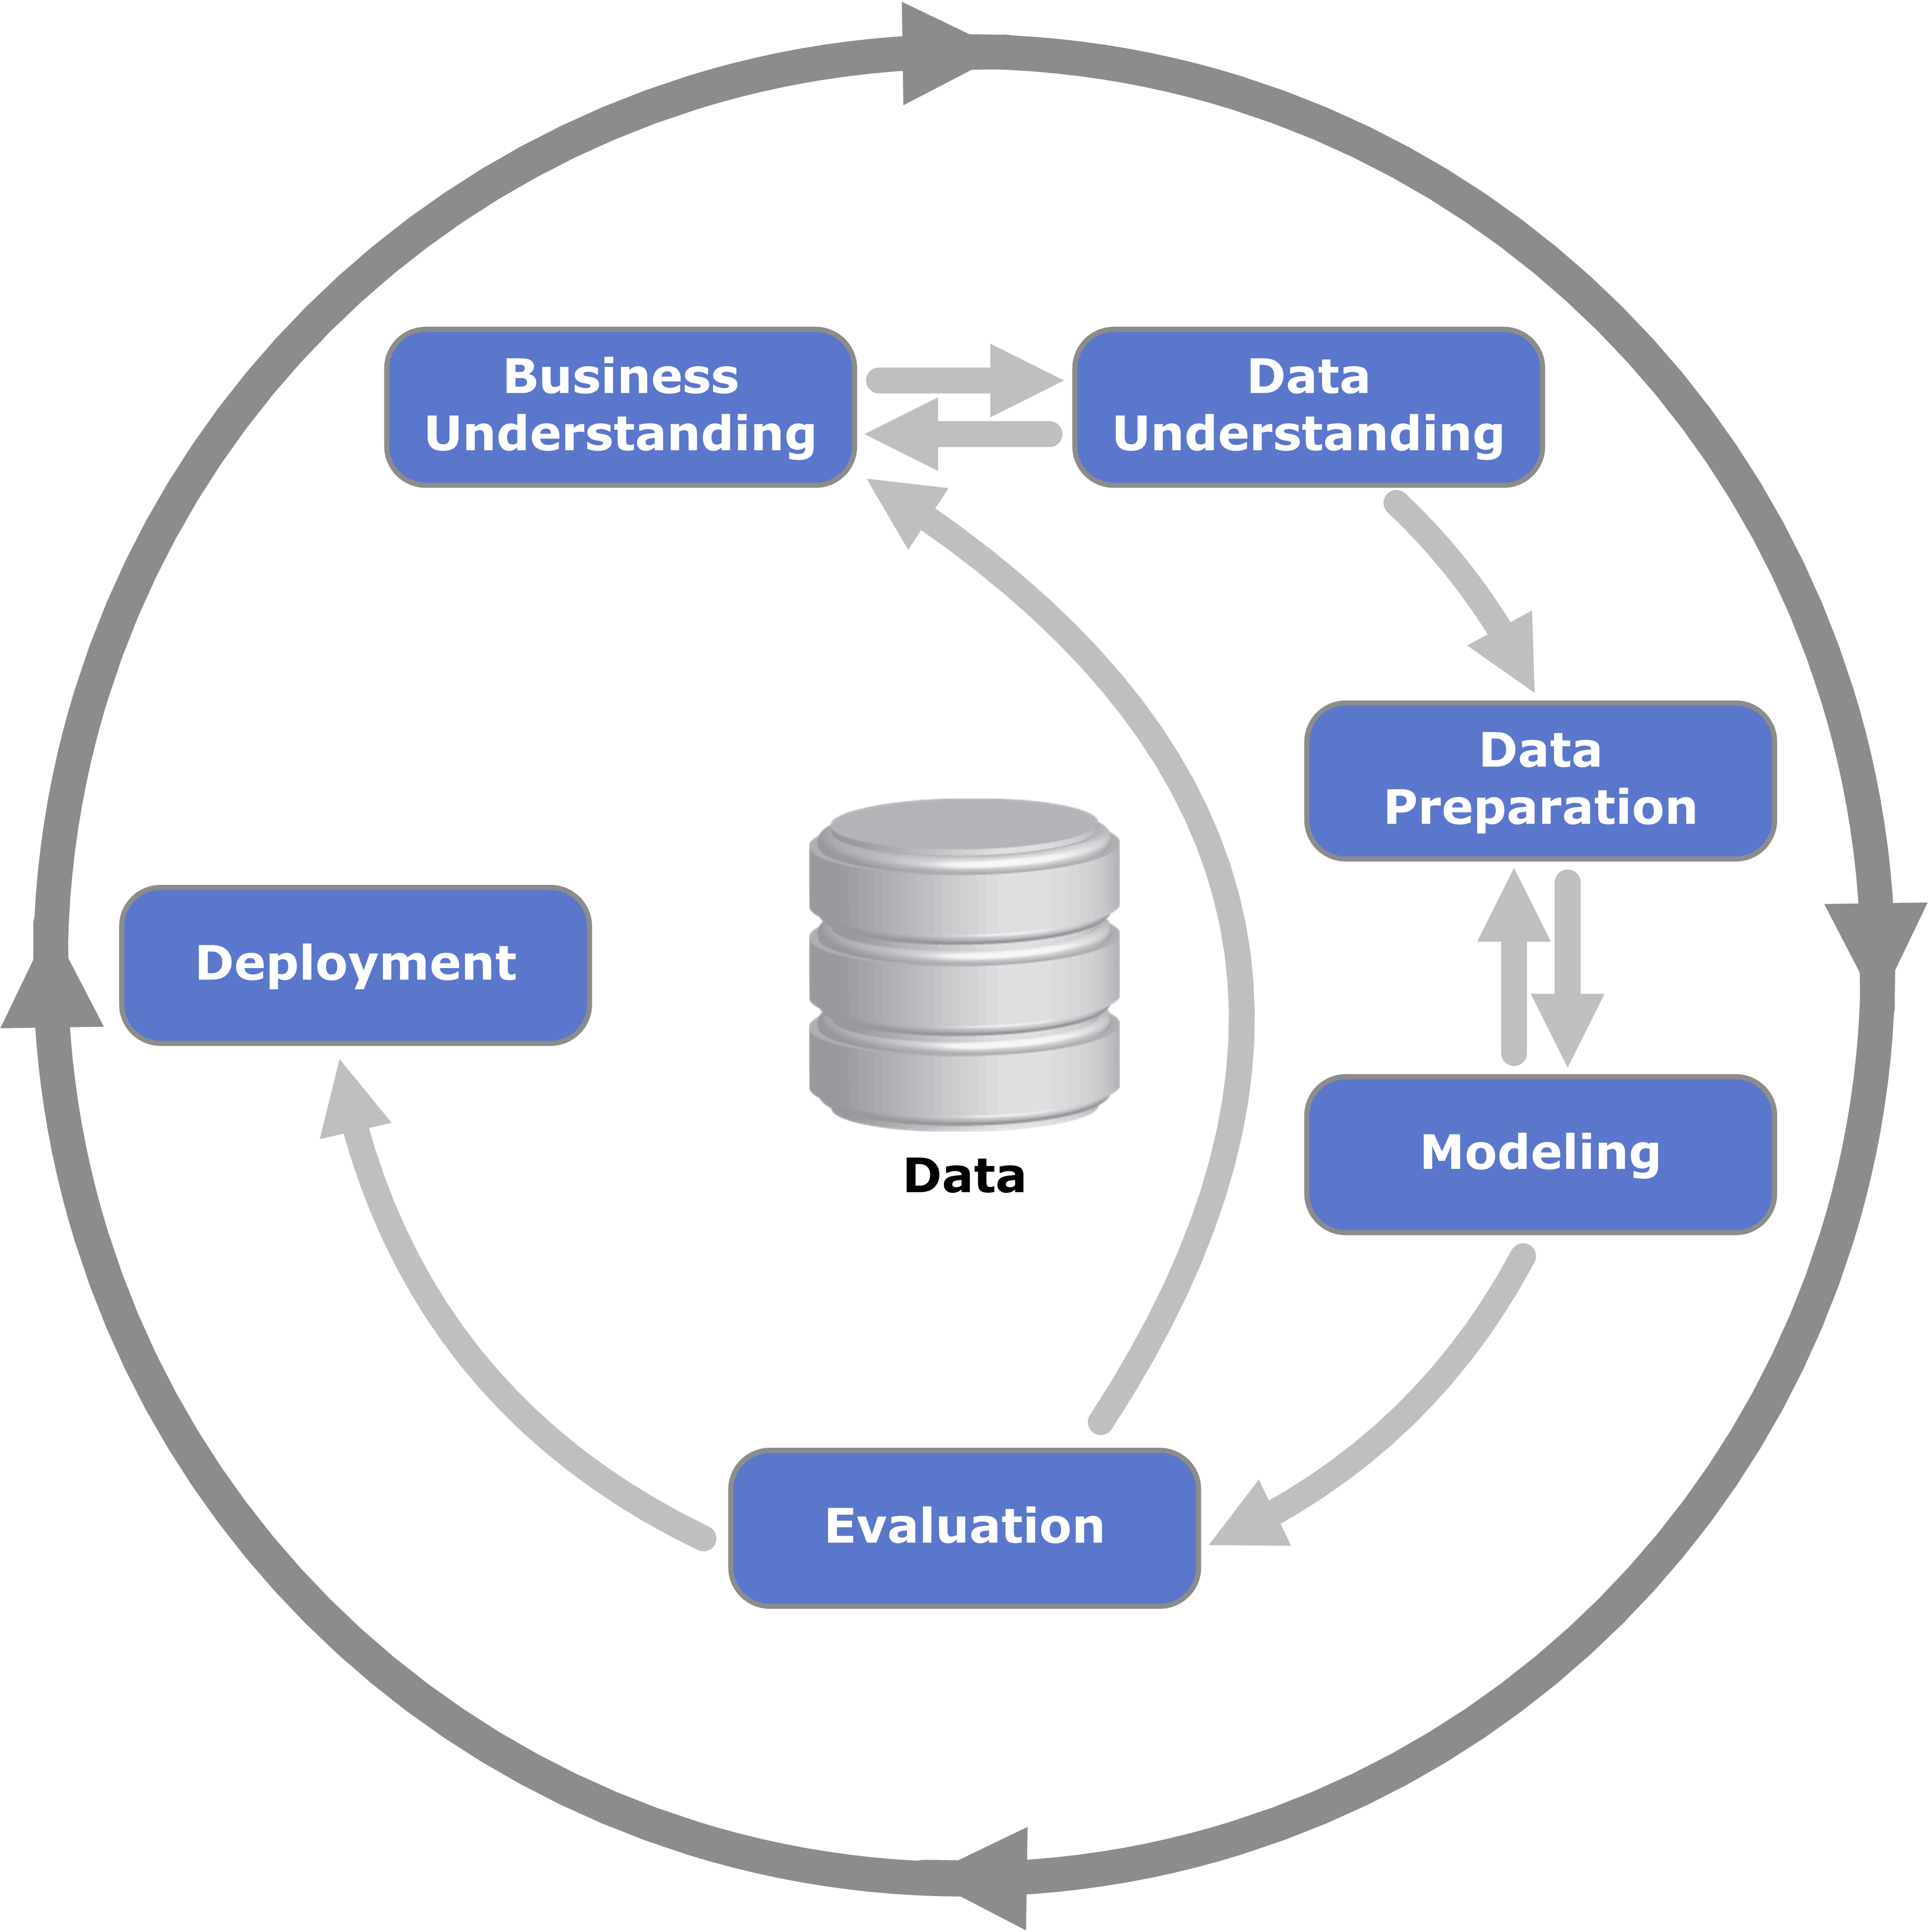

## Índice

1. Business Understanding
2. Configuración inicial
3. Data Understanding / EDA
4. Data Preparation
   - 4.1 Pipeline A: robustez al ruido (todas las variables)
   - 4.2 Pipeline B: selección de características (ReliefF → 18 variables)
5. Modeling
   - 5.1 Random Forest con ruido (todas las variables)
   - 5.2 Random Forest optimizado (18 variables, StratifiedGroupKFold)
   - 5.3 TabICL (v1)
   - 5.4 TabICL (v2)
   - 5.5 Mitra
   - 5.6 TabDPT
6. Evaluation
7. Deployment

## 1. Business Understanding

Problema: Los trastornos de ansiedad son problemas de salud mental globales, pero los métodos tradicionales de detección (como los cuestionarios de autoreporte) tienen limitaciones al no ser dinámicos ni cuantitativos

La Solución Tecnológica: El uso de tecnología wearable permite el monitoreo en tiempo real de la respuesta del sistema nervioso autónomo mediante señales como la actividad electrodérmica (EDA), el volumen de pulso sanguíneo (BVP) y la electrocardiografía (ECG).

Objetivo: Evaluar la resiliencia al ruido ambiental en la clasificación de estados de ansiedad, estableciendo un modelo base robusto mediante Random Forest para posteriormente contrastarlo con arquitecturas avanzadas de Transformers, cuantificando el rendimiento y la degradación de los modelos al inyectar niveles controlados de ruido gaussiano sintético en el dataset WESAD preprocesado (may14_feats4.csv) mediante métricas como F1-Score, Curva ROC, AUC y Accuracy, y validando los resultados con K-Fold Cross-Validation para evitar sobreajuste; este análisis, desarrollado con librerías estándar de Python y posteriormente escalado a frameworks de Deep Learning, permitirá determinar qué paradigma algorítmico mantiene mejor su capacidad discriminativa en entornos ruidosos para el desarrollo de sistemas wearables de detección de ansiedad viables en el mundo real, comparando el desempeño de Random Forest frente a cuatro Modelos Fundacionales Tabulares (TabICL v1, TabICL v2, Mitra y TabDPT).

## 2. Configuración inicial

In [ ]:
# Manipulación de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y selección de características
from sklearn.preprocessing import StandardScaler, label_binarize
from imblearn.under_sampling import RandomUnderSampler
from skrebate import ReliefF

# Modelos y validación cruzada
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, StratifiedGroupKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)

# Métricas
from sklearn.metrics import (roc_curve, auc, classification_report,
                             roc_auc_score, accuracy_score, f1_score)

# Transformer tabular
import time
from tabicl import TabICLClassifier
from tabdpt import TabDPTClassifier

# Mitra (AutoGluon): interfaz sklearn si está disponible; de lo contrario se usa TabularPredictor
try:
    from autogluon.tabular.models.mitra.sklearn_interface import MitraClassifier
    usar_sklearn_mitra = True
except ImportError:
    from autogluon.tabular import TabularPredictor
    usar_sklearn_mitra = False

# Exportar métricas
import os

pd.reset_option('display.max_rows'); pd.reset_option('display.max_columns')

c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Data Understanding / EDA

### 3.1 Carga de datos y calidad estructural

In [2]:
#Carga de data
df = pd.read_csv("../anxietyFB-main/data/may14_feats4.csv")
df

,Unnamed: 0,net_acc_C_mean,net_acc_C_std,net_acc_C_min,net_acc_C_max,net_acc_mean,net_acc_std,net_acc_min,net_acc_max,EDA_mean,...,Resp_C_Inhal_std,Resp_C_Exhal_mean,Resp_C_Exhal_std,Resp_C_I/E,TEMP_drange,TEMP_C_drange,TEMP_slope,TEMP_C_slope,subject,label
0,0,0.000531,0.000086,0.000371,0.000788,0.025961,0.013811,0.000000,0.087383,1.303625,...,0.622539,1.839898,0.741267,1.113083,1.003357,1.014887,-0.000253,-1.377799e-06,2,1
1,1,0.000426,0.000004,0.000400,0.000443,0.027640,0.010597,0.002752,0.054356,0.892549,...,0.189863,1.487778,0.439986,1.003521,1.002524,1.016588,-0.000161,-6.099829e-06,2,1
2,2,0.000427,0.000004,0.000407,0.000444,0.028389,0.006937,0.000000,0.066053,0.598712,...,0.345404,1.431053,0.437193,0.927337,1.003640,1.010799,0.000535,1.041127e-06,2,1
3,3,0.000460,0.000050,0.000397,0.000643,0.033268,0.007670,0.000000,0.074998,0.504760,...,0.252339,1.567381,0.678817,0.942731,1.003355,1.015345,-0.000256,-3.158520e-06,2,1
4,4,0.000441,0.000003,0.000427,0.000458,0.037021,0.001284,0.027522,0.043347,0.456286,...,0.138846,1.338357,0.116270,1.007579,1.001957,1.015297,0.000260,-4.752758e-06,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,572,0.000608,0.000018,0.000519,0.000721,0.029596,0.007250,0.002064,0.070870,1.019429,...,0.925958,2.198571,0.806926,0.969352,1.003035,1.009289,-0.000225,-1.991283e-06,17,0
573,573,0.000608,0.000004,0.000593,0.000625,0.030401,0.000552,0.028898,0.031650,1.015634,...,0.449312,1.729810,0.163246,0.999835,1.002431,1.007332,-0.000249,2.515800e-07,17,0
574,574,0.000607,0.000006,0.000536,0.000678,0.029762,0.000721,0.026834,0.035779,1.012849,...,0.561151,1.982527,0.814294,1.034089,1.002741,1.006967,-0.000174,-2.817866e-07,17,0
575,575,0.000603,0.000009,0.000512,0.000682,0.033337,0.001668,0.028898,0.041283,1.005232,...,0.203108,1.604202,0.174612,0.931954,1.001217,1.007922,0.000068,-1.085821e-06,17,0


In [3]:
df = df.drop(columns=["Unnamed: 0"])
df

,net_acc_C_mean,net_acc_C_std,net_acc_C_min,net_acc_C_max,net_acc_mean,net_acc_std,net_acc_min,net_acc_max,EDA_mean,EDA_std,...,Resp_C_Inhal_std,Resp_C_Exhal_mean,Resp_C_Exhal_std,Resp_C_I/E,TEMP_drange,TEMP_C_drange,TEMP_slope,TEMP_C_slope,subject,label
0,0.000531,0.000086,0.000371,0.000788,0.025961,0.013811,0.000000,0.087383,1.303625,0.151736,...,0.622539,1.839898,0.741267,1.113083,1.003357,1.014887,-0.000253,-1.377799e-06,2,1
1,0.000426,0.000004,0.000400,0.000443,0.027640,0.010597,0.002752,0.054356,0.892549,0.142093,...,0.189863,1.487778,0.439986,1.003521,1.002524,1.016588,-0.000161,-6.099829e-06,2,1
2,0.000427,0.000004,0.000407,0.000444,0.028389,0.006937,0.000000,0.066053,0.598712,0.066870,...,0.345404,1.431053,0.437193,0.927337,1.003640,1.010799,0.000535,1.041127e-06,2,1
3,0.000460,0.000050,0.000397,0.000643,0.033268,0.007670,0.000000,0.074998,0.504760,0.018053,...,0.252339,1.567381,0.678817,0.942731,1.003355,1.015345,-0.000256,-3.158520e-06,2,1
4,0.000441,0.000003,0.000427,0.000458,0.037021,0.001284,0.027522,0.043347,0.456286,0.036839,...,0.138846,1.338357,0.116270,1.007579,1.001957,1.015297,0.000260,-4.752758e-06,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,0.000608,0.000018,0.000519,0.000721,0.029596,0.007250,0.002064,0.070870,1.019429,0.007279,...,0.925958,2.198571,0.806926,0.969352,1.003035,1.009289,-0.000225,-1.991283e-06,17,0
573,0.000608,0.000004,0.000593,0.000625,0.030401,0.000552,0.028898,0.031650,1.015634,0.001740,...,0.449312,1.729810,0.163246,0.999835,1.002431,1.007332,-0.000249,2.515800e-07,17,0
574,0.000607,0.000006,0.000536,0.000678,0.029762,0.000721,0.026834,0.035779,1.012849,0.002051,...,0.561151,1.982527,0.814294,1.034089,1.002741,1.006967,-0.000174,-2.817866e-07,17,0
575,0.000603,0.000009,0.000512,0.000682,0.033337,0.001668,0.028898,0.041283,1.005232,0.003284,...,0.203108,1.604202,0.174612,0.931954,1.001217,1.007922,0.000068,-1.085821e-06,17,0


In [4]:
df.shape

(577, 120)

In [5]:
df.isnull().sum()

net_acc_C_mean    0
net_acc_C_std     0
net_acc_C_min     0
net_acc_C_max     0
net_acc_mean      0
                 ..
TEMP_C_drange     0
TEMP_slope        0
TEMP_C_slope      0
subject           0
label             0
Length: 120, dtype: int64

In [6]:
df.isnull().sum().sum() #Al no poder ver todas las columnas

np.int64(0)

### 3.2 Distribución de clases

In [7]:
df['label'].value_counts(normalize=True) * 100

label
1    54.072790
2    30.329289
0    15.597920
Name: proportion, dtype: float64

C:\Users\TEFO3\AppData\Local\Temp\ipykernel_27780\2510921168.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='label', palette='viridis')


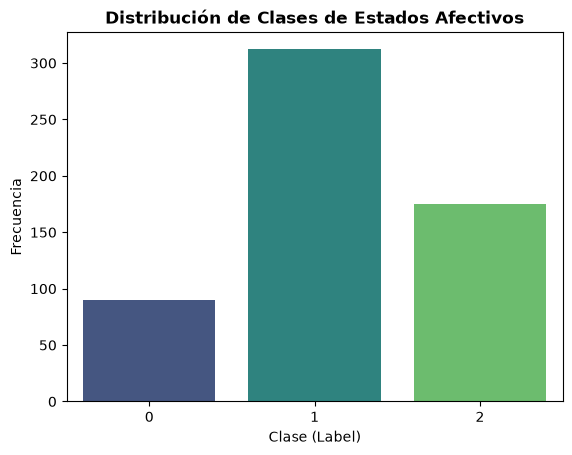

In [8]:
# Visualización del Desbalanceo de Clases
plt.figure()
ax = sns.countplot(data=df, x='label', palette='viridis')
plt.title("Distribución de Clases de Estados Afectivos", fontweight='bold')
plt.xlabel("Clase (Label)")
plt.ylabel("Frecuencia")
plt.show()

### 3.3 Correlaciones

In [9]:
correlations = df.corr()
correlations["label"].sort_values(ascending=False)


label           1.000000
EDA_SCL_max     0.647831
EDA_SCL_mean    0.641174
EDA_SCL_min     0.629194
ECG_bpm         0.548184
                  ...   
ECG_min        -0.304055
ECG_pnn20      -0.321408
EDA_SCR_min    -0.425529
Resp_C_rate    -0.526967
ECG_ibi        -0.529081
Name: label, Length: 120, dtype: float64

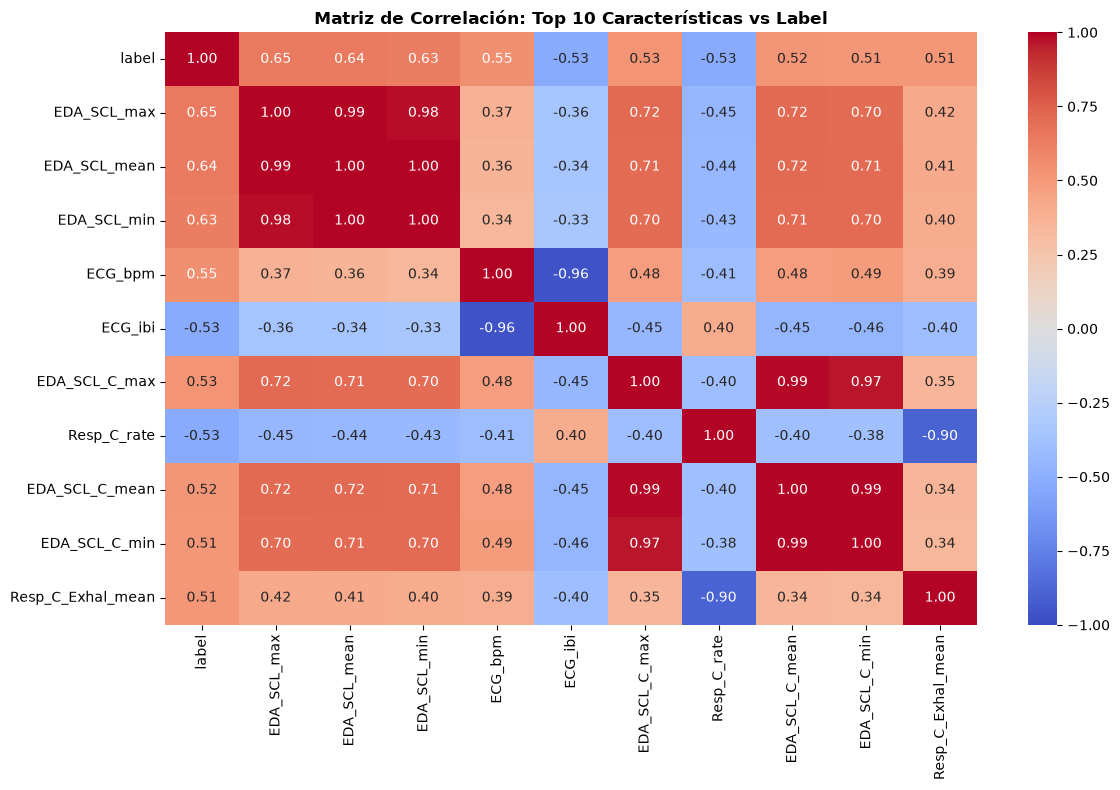

In [10]:
top_10_corr_vars = df.corr()['label'].abs().sort_values(ascending=False).head(11).index
df_top_10 = df[top_10_corr_vars]

plt.figure(figsize=(12, 8))
sns.heatmap(df_top_10.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlación: Top 10 Características vs Label", fontweight='bold')
plt.tight_layout()
plt.show()

### 3.4 Hallazgos del EDA

**Calidad Estructural e Integridad**: El conjunto de datos presenta una integridad del 100%. Tras eliminar el índice residual (Unnamed: 0), la matriz de datos consta de 577 instancias y 120 columnas: 118 variables predictoras, la etiqueta (label) y el identificador de sujeto (subject). La validación de valores nulos (df.isnull().sum().sum()) confirmó la ausencia total de datos faltantes, lo que exime al proyecto de aplicar técnicas de imputación complejas y garantiza que las métricas extraídas de los sensores son continuas y completas.

**Desbalanceo de Clases**: El análisis de la distribución porcentual de la variable objetivo (label) y su respectivo gráfico de conteo revelan un desbalanceo en las clases de los estados afectivos. Este hallazgo empírico justifica plenamente la decisión metodológica de utilizar métricas de evaluación robustas para clases desbalanceadas, tales como el F1-Score, Curva ROC y AUC, y la necesidad de aplicar Stratified K-Fold Cross Validation en las siguientes etapas.

**Poder Predictivo y Multicolinealidad**: La extracción de las correlaciones absolutas contra la variable label y su posterior visualización en el mapa de calor (Top 10) validan lo establecido en la revisión de la literatura. Biomarcadores específicos del sistema nervioso autónomo (como la actividad electrodérmica máxima y métricas cardíacas) presentan la mayor correlación con la etiqueta de ansiedad. Asimismo, el mapa de calor revela la presencia de multicolinealidad entre algunas características derivadas de la misma señal, lo que sugiere que algoritmos de ensamble como Random Forest serán ideales por su capacidad intrínseca para manejar variables correlacionadas sin necesidad de eliminarlas manualmente.

## 4. Data Preparation

### 4.1 Pipeline A: robustez al ruido (todas las variables)

Estandarización de las variables, construcción del *Noise Engine* y generación de los datasets contaminados con distintos niveles de SNR.

#### 4.1.1 Separación de variables y estandarización

In [11]:
#Separar variable objetivo de las caracteristicas
X = df.drop(columns=["label", "subject"])
y = df["label"]

In [12]:
#Estandarizamos las variables con Standart Scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-0.25814057,  5.28062755, -1.45955378, ...,  0.13080757,
        -0.43525933, -0.3316155 ],
       [-1.43778578, -0.47704779, -1.13249042, ...,  0.16642096,
        -0.26613935, -0.99707857],
       [-1.4287397 , -0.49531386, -1.04955118, ...,  0.04522491,
         1.0097774 ,  0.00927732],
       ...,
       [ 0.60511717, -0.34271062,  0.41832108, ..., -0.03498634,
        -0.28956599, -0.1771574 ],
       [ 0.55736832, -0.16100534,  0.14289944, ..., -0.01499737,
         0.15305494, -0.29046784],
       [ 0.59296951, -0.51207621,  0.95351465, ..., -0.04729078,
        -0.97720921, -0.14511061]], shape=(577, 118))

In [13]:
#Se transforma a dataframe
X_scaled_df = pd.DataFrame(X_scaled, columns= X.columns)
X_scaled_df

,net_acc_C_mean,net_acc_C_std,net_acc_C_min,net_acc_C_max,net_acc_mean,net_acc_std,net_acc_min,net_acc_max,EDA_mean,EDA_std,...,Resp_C_rate,Resp_C_Inhal_mean,Resp_C_Inhal_std,Resp_C_Exhal_mean,Resp_C_Exhal_std,Resp_C_I/E,TEMP_drange,TEMP_C_drange,TEMP_slope,TEMP_C_slope
0,-0.258141,5.280628,-1.459554,0.816056,-0.388016,2.553181,-1.067277,1.996634,-0.250790,0.911556,...,0.247000,-0.477309,0.054507,-0.552747,0.604169,0.475343,-0.061238,0.130808,-0.435259,-0.331616
1,-1.437786,-0.477048,-1.132490,-0.921396,-0.206106,1.675475,-0.850440,0.195723,-0.404933,0.815679,...,1.516810,-1.577720,-0.980722,-1.492152,-0.202862,-0.332646,-0.401218,0.166421,-0.266139,-0.997079
2,-1.428740,-0.495314,-1.049551,-0.915156,-0.124924,0.676310,-1.067277,0.833546,-0.515114,0.067814,...,1.225702,-1.607926,-0.608571,-1.643486,-0.210345,-0.894480,0.054616,0.045225,1.009777,0.009277
3,-1.056573,2.769038,-1.162224,0.086686,0.403776,0.876386,-1.067277,1.321293,-0.550344,-0.417524,...,1.267935,-1.610017,-0.831241,-1.279782,0.436885,-0.780950,-0.062004,0.140393,-0.440556,-0.582568
4,-1.271272,-0.561905,-0.824206,-0.849292,0.810384,-0.866957,1.101100,-0.404581,-0.568520,-0.230756,...,2.550108,-1.723712,-1.102785,-1.890784,-1.069991,-0.302721,-0.632641,0.139382,0.505718,-0.807239
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,0.618659,0.485390,0.227404,0.479103,0.005884,0.761792,-0.904649,1.096179,-0.357356,-0.524644,...,-0.748013,0.438252,0.780475,0.404141,0.780046,-0.584627,-0.192584,0.013626,-0.384049,-0.418072
573,0.614749,-0.506421,1.061493,-0.006218,0.093090,-1.067061,1.209519,-1.042404,-0.358779,-0.579712,...,0.741798,-0.606543,-0.359958,-0.846446,-0.944157,-0.359828,-0.439169,-0.027350,-0.428211,-0.101991
574,0.605117,-0.342711,0.418321,0.259322,0.023795,-1.020707,1.046890,-0.817290,-0.359823,-0.576622,...,0.708506,-0.494480,-0.092369,-0.172232,0.799782,-0.107214,-0.312744,-0.034986,-0.289566,-0.177157
575,0.557368,-0.161005,0.142899,0.282202,0.411213,-0.762112,1.209519,-0.517138,-0.362680,-0.564358,...,1.471385,-1.192358,-0.949032,-1.181550,-0.913712,-0.860430,-0.934746,-0.014997,0.153055,-0.290468


#### 4.1.2 Motor de ruido (Noise Engine) y niveles de SNR

In [14]:
# Construcción del Motor de Ruido (Noise Engine)
def add_gaussian_noise(signal, snr):
    """
    Inyecta ruido gaussiano a una señal dada una Relación Señal-Ruido (SNR).
    Basado en la Ecuación (1) y (2) del documento de referencia:
    Potencia de la señal E(S^2) / SNR = Varianza del ruido (sigma^2).
    """
    # Calculamos la potencia de la señal: E(S^2)
    signal_power = np.mean(signal ** 2)
    
    # Calculamos la varianza del ruido según el SNR requerido
    # Si SNR es muy bajo (ej. 0.01), el ruido será enorme.
    noise_variance = signal_power / snr
    
    # Generamos el ruido gaussiano N(0, sigma^2)
    noise = np.random.normal(loc=0.0, scale=np.sqrt(noise_variance), size=signal.shape)
    
    # Retornamos la señal contaminada con ruido
    return signal + noise

def generate_noisy_datasets(X_df, snr_levels):
    """
    Genera un diccionario con múltiples DataFrames, cada uno contaminado
    con un nivel específico de ruido SNR.
    """
    datasets = {}
    for snr in snr_levels:
        # Aplicamos la función de ruido columna por columna
        noisy_X = X_df.apply(lambda col: add_gaussian_noise(col, snr))
        datasets[snr] = noisy_X
        print(f"Dataset generado para SNR: {snr}")
        
    return datasets

In [15]:
# Definición de los Niveles SNR (Signal-to-Noise Ratios)
# Según el artículo, se evalúan niveles desde mucha interferencia (0.01) 
# hasta poca interferencia (0.6).
snr_list = [0.01, 0.1, 0.15, 0.4, 0.6]

#### 4.1.3 Generación de los datasets ruidosos

In [16]:
print("--- INICIANDO INYECCIÓN DE RUIDO SINTÉTICO ---")
# Generamos los datasets ruidosos basados en las características escaladas
noisy_X_dict = generate_noisy_datasets(X_scaled_df, snr_list)

# Agregamos el dataset base (sin ruido adicional) al diccionario para la validación inicial
noisy_X_dict['Baseline'] = X_scaled_df
print(f"\nPreparación completada: {len(noisy_X_dict)} escenarios generados.")

--- INICIANDO INYECCIÓN DE RUIDO SINTÉTICO ---
Dataset generado para SNR: 0.01
Dataset generado para SNR: 0.1
Dataset generado para SNR: 0.15
Dataset generado para SNR: 0.4
Dataset generado para SNR: 0.6

Preparación completada: 6 escenarios generados.


#### 4.1.4 Validación visual del efecto del ruido

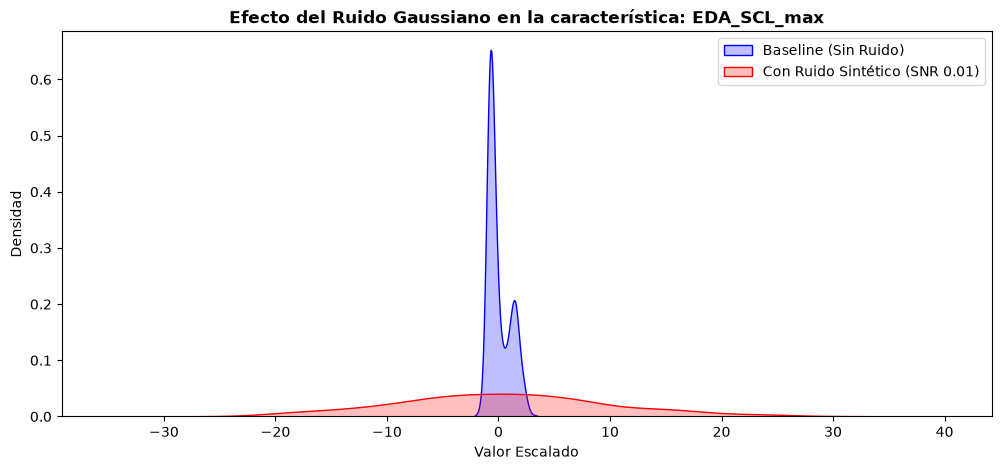

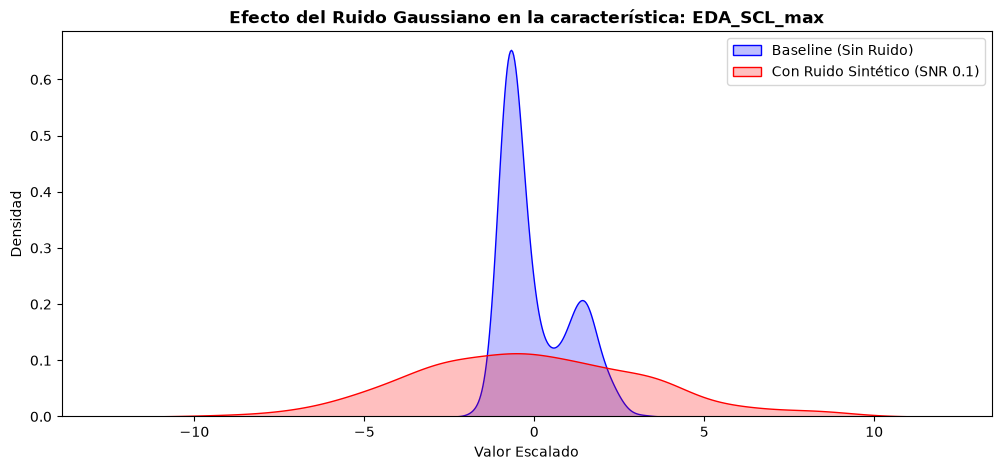

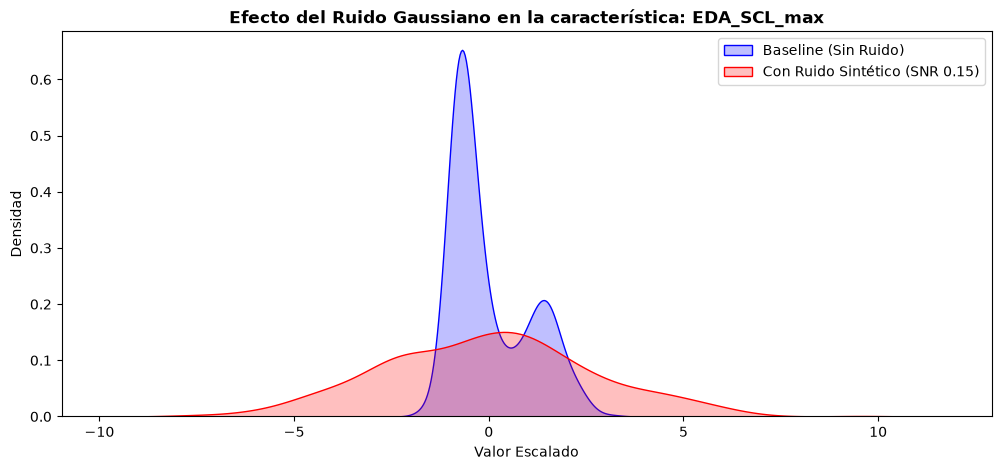

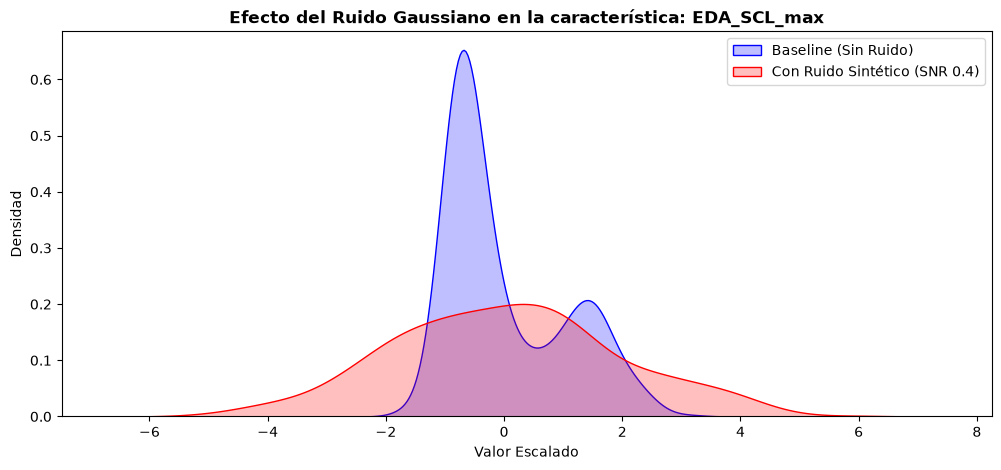

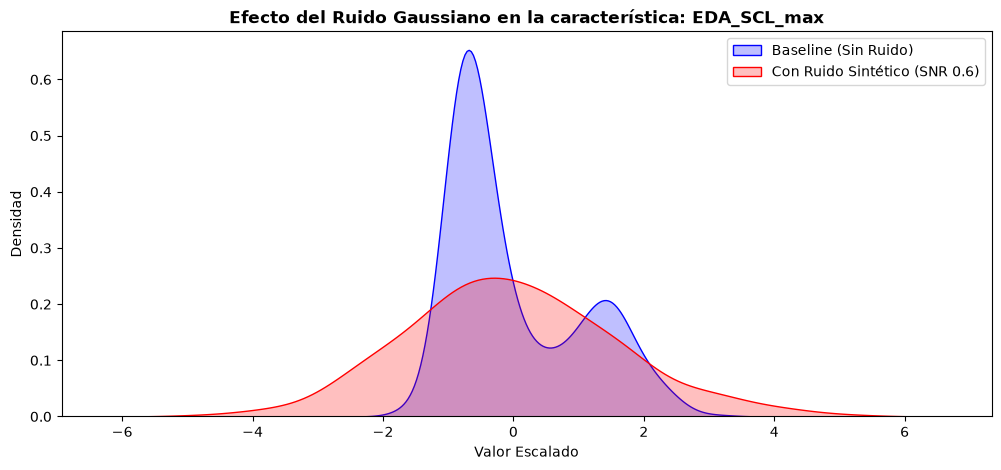

In [17]:
feature_to_plot = 'EDA_SCL_max'  # El biomarcador más importante

for snr in snr_list:
    plt.figure(figsize=(12, 5))
    sns.kdeplot(noisy_X_dict['Baseline'][feature_to_plot], label='Baseline (Sin Ruido)', fill=True, color='blue')
    sns.kdeplot(noisy_X_dict[snr][feature_to_plot], label=f'Con Ruido Sintético (SNR {snr})', fill=True, color='red')
    plt.title(f"Efecto del Ruido Gaussiano en la característica: {feature_to_plot}", fontweight='bold')
    plt.xlabel("Valor Escalado")
    plt.ylabel("Densidad")
    plt.legend()
    plt.show()

**Validación Visual de la Degradación (El Efecto del Ruido)**: La gráfica del biomarcador principal (EDA_SCL_max) demuestra perfectamente el funcionamiento del Noise Engine. La distribución Baseline (azul) muestra la señal original estandarizada, fuertemente concentrada alrededor del cero y con picos definidos; esta es la estructura limpia de donde los algoritmos extraen patrones fácilmente. Por el contrario, la distribución con Ruido Extremo a SNR 0.01 (rojo) ilustra cómo una interferencia severa "aplasta" la información original, dispersando los datos en un rango masivo (de -40 a +20). Visual y matemáticamente, la varianza del ruido ha ahogado por completo la varianza biológica de la señal del paciente.

**Estandarización como Pilar Técnico**: La aplicación del StandardScaler fue un paso fundamental antes de inyectar el ruido. Garantizó que las perturbaciones gaussianas se aplicaran de manera equitativa basándose en la potencia real de cada señal, evitando que variables con escalas naturalmente grandes (como los milivoltios de un EMG) dominaran artificialmente sobre variables de rangos pequeños (como las variaciones de temperatura).

**Simulación de la Incertidumbre Clínica**: Al generar sistemáticamente múltiples datasets con distintos niveles de Relación Señal-Ruido (desde una interferencia catastrófica de 0.01 hasta niveles más leves como 0.6), el proyecto ha dejado de ser un análisis de "laboratorio perfecto". Ahora se ha transformado en un entorno de prueba de estrés real para la Inteligencia Artificial.

### 4.2 Pipeline B: selección de características (ReliefF → 18 variables)

Balanceo por *undersampling*, estandarización, ranking de variables con ReliefF y selección de las 18 mejores por el método del codo.

#### 4.2.1 Variables, grupos (sujetos) y undersampling

In [18]:
X = df.drop(columns=['label', 'subject'])
y = df['label']
groups = df['subject'] # Necesario para StratifiedGroupKFold 


In [19]:
# Undersampling (Igualar clases)
# Añadimos 'subject' a X temporalmente para no perder a qué paciente pertenece cada fila tras el recorte
X_temp = X.copy()
X_temp['subject'] = groups

rus = RandomUnderSampler(random_state=42)
X_res, y_res = rus.fit_resample(X_temp, y)

In [20]:
# Separamos el 'subject' del dataset ya balanceado
groups_res = X_res['subject']
X_res = X_res.drop(columns=['subject'])

print("--- DISTRIBUCIÓN TRAS UNDERSAMPLING ---")
print(y_res.value_counts())

--- DISTRIBUCIÓN TRAS UNDERSAMPLING ---
label
0    90
1    90
2    90
Name: count, dtype: int64


#### 4.2.2 Estandarización y ReliefF

In [21]:
# Escalar los datos (ReliefF es sensible a las escalas)
scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)

In [22]:
# Aplicar ReliefF
print("\nCalculando importancia con ReliefF (esto puede tardar unos segundos)...")
# Usamos n_neighbors=20 (estándar para datasets medianos)
fs = ReliefF(n_features_to_select=X_res_scaled.shape[1], n_neighbors=20, n_jobs=-1)
fs.fit(X_res_scaled, y_res.values)

relief_scores = pd.DataFrame({
    'Feature': X_res.columns,
    'Score': fs.feature_importances_
}).sort_values(by='Score', ascending=False)


Calculando importancia con ReliefF (esto puede tardar unos segundos)...


#### 4.2.3 Método del codo y selección de las 18 variables

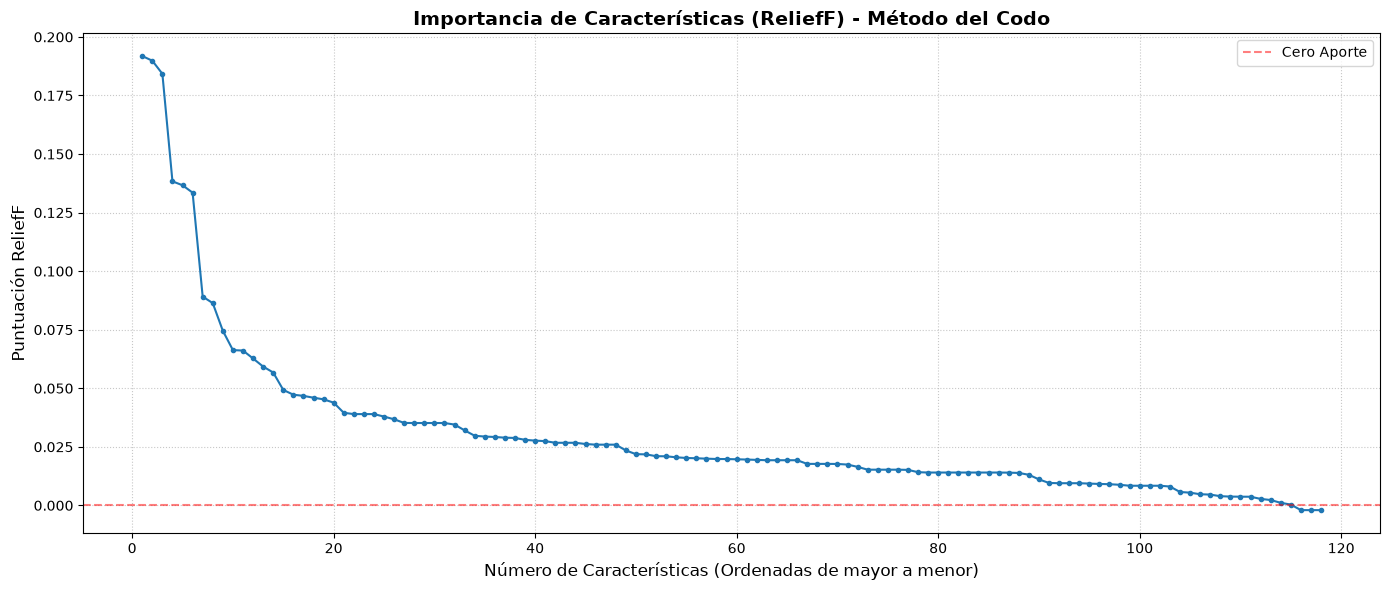

In [23]:
# Visualización para encontrar el "Codo" (Optimal Number of Features)
plt.figure(figsize=(14, 6))
plt.plot(range(1, len(relief_scores) + 1), relief_scores['Score'], marker='.', linestyle='-')
plt.title('Importancia de Características (ReliefF) - Método del Codo', fontweight='bold', fontsize=14)
plt.xlabel('Número de Características (Ordenadas de mayor a menor)', fontsize=12)
plt.ylabel('Puntuación ReliefF', fontsize=12)

# Líneas guía visuales
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Cero Aporte')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [24]:
# Visualización de las 30 características con mayor puntuación ReliefF
print("\n--- TOP 30 CARACTERÍSTICAS SEGÚN RELIEF ---")
relief_scores.head(30)


--- TOP 30 CARACTERÍSTICAS SEGÚN RELIEF ---


,Feature,Score
19,EDA_SCL_max,0.191845
16,EDA_SCL_mean,0.189847
18,EDA_SCL_min,0.184265
55,EDA_SCL_C_max,0.138345
52,EDA_SCL_C_mean,0.136683
54,EDA_SCL_C_min,0.133518
95,ECG_bpm,0.089145
96,ECG_ibi,0.086363
108,Resp_C_rate,0.074564
111,Resp_C_Exhal_mean,0.066299


Mediante la inspección visual de la curva de importancia (Método del Codo), se observa un punto de inflexión en el atributo 18, a partir del cual la ganancia informativa marginal disminuye considerablemente.

In [25]:
# Seleccionar las 18 mejores características según ReliefF
top_18_features = relief_scores['Feature'].head(18).tolist()
X_selected = X_res[top_18_features]

Selección de Características (ReliefF a 18 variables): Al reducir de 118 a 18 características, eliminamos la redundancia y el ruido colineal. ReliefF fue elegido por su capacidad matemática para evaluar interacciones complejas entre variables y distinguir entre instancias vecinas de distintas clases.

## 5. Modeling

### 5.1 Random Forest con ruido (todas las variables)

In [26]:
# Configuración del Algoritmo y Validación Cruzada
# Usamos class_weight='balanced' para contrarrestar el desbalanceo de clases (0, 1, 2)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#Accuracy, F1-Score (ponderado por el desbalanceo) y AUC (One-vs-Rest)
scoring_metrics = {'ACC': 'accuracy', 'F1': 'f1_weighted', 'AUC': 'roc_auc_ovr_weighted'}
results_list = []

In [27]:
# Bucle de Evaluación para el Baseline y cada nivel de Ruido (SNR)
for snr_name, X_noisy in noisy_X_dict.items():
    print(f"Entrenando y evaluando dataset: {snr_name}...")
    
    # Validación cruzada estricta
    cv_results = cross_validate(rf_model, X_noisy, y, cv=cv_stratified, scoring=scoring_metrics)
    
    # Extracción de la media de las métricas en los 5 pliegues
    results_list.append({
        'SNR': snr_name,
        'Accuracy': cv_results['test_ACC'].mean(),
        'F1_Score': cv_results['test_F1'].mean(),
        'AUC': cv_results['test_AUC'].mean()
    })

# Consolidación de Resultados en un DataFrame
results_df = pd.DataFrame(results_list)
print("\n--- RESULTADOS FINALES DE DEGRADACIÓN ---")
results_df

Entrenando y evaluando dataset: 0.01...
Entrenando y evaluando dataset: 0.1...
Entrenando y evaluando dataset: 0.15...
Entrenando y evaluando dataset: 0.4...
Entrenando y evaluando dataset: 0.6...
Entrenando y evaluando dataset: Baseline...

--- RESULTADOS FINALES DE DEGRADACIÓN ---


,SNR,Accuracy,F1_Score,AUC
0,0.01,0.506102,0.451299,0.535593
1,0.1,0.649910,0.592780,0.734948
2,0.15,0.675892,0.626667,0.769373
3,0.4,0.774723,0.728051,0.886540
4,0.6,0.817991,0.785263,0.917211
5,Baseline,0.968846,0.968881,0.998111


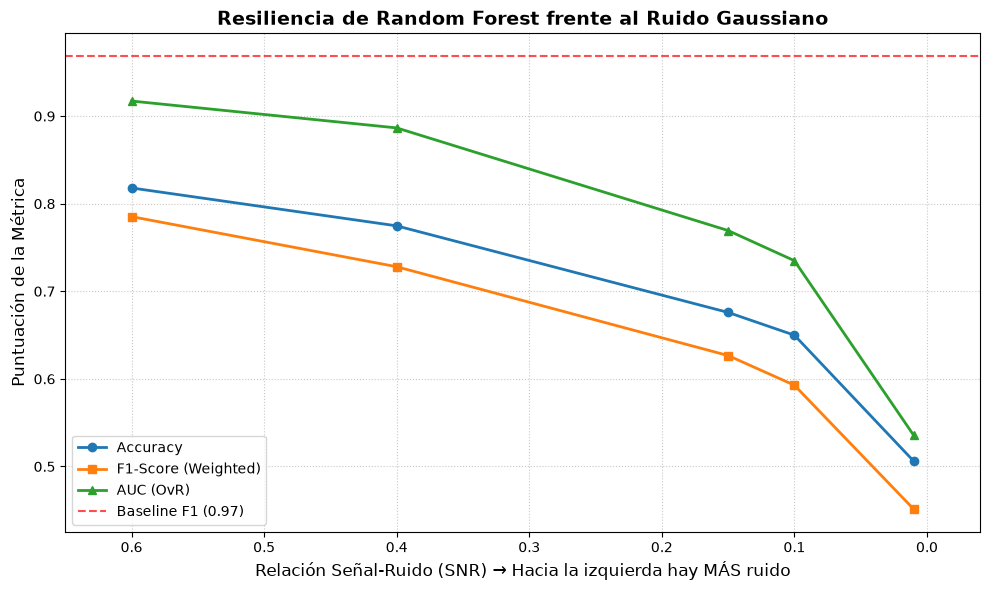

In [28]:
# Visualización de la Degradación del Rendimiento
# Separamos el Baseline de los valores numéricos de SNR para la gráfica
numeric_results = results_df[results_df['SNR'] != 'Baseline'].copy()
numeric_results['SNR'] = numeric_results['SNR'].astype(float)
# Ordenamos de menor ruido (0.6) a mayor ruido extremo (0.01)
numeric_results = numeric_results.sort_values(by='SNR', ascending=False) 

baseline_f1 = results_df[results_df['SNR'] == 'Baseline']['F1_Score'].values[0]
baseline_auc = results_df[results_df['SNR'] == 'Baseline']['AUC'].values[0]

plt.figure(figsize=(10, 6))
plt.plot(numeric_results['SNR'], numeric_results['Accuracy'], marker='o', linewidth=2, label='Accuracy')
plt.plot(numeric_results['SNR'], numeric_results['F1_Score'], marker='s', linewidth=2, label='F1-Score (Weighted)')
plt.plot(numeric_results['SNR'], numeric_results['AUC'], marker='^', linewidth=2, label='AUC (OvR)')

# Línea base de referencia (El techo de rendimiento sin ruido)
plt.axhline(y=baseline_f1, color='red', linestyle='--', alpha=0.7, label=f'Baseline F1 ({baseline_f1:.2f})')

plt.title('Resiliencia de Random Forest frente al Ruido Gaussiano', fontsize=14, fontweight='bold')
plt.xlabel('Relación Señal-Ruido (SNR) → Hacia la izquierda hay MÁS ruido', fontsize=12)
plt.ylabel('Puntuación de la Métrica', fontsize=12)
# Invertimos el eje X para que visualmente la curva "caiga" conforme aumenta el ruido
plt.xlim(max(numeric_results['SNR']) + 0.05, min(numeric_results['SNR']) - 0.05) 
plt.legend(loc='lower left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()


--- GENERANDO CURVAS ROC (BASELINE) ---


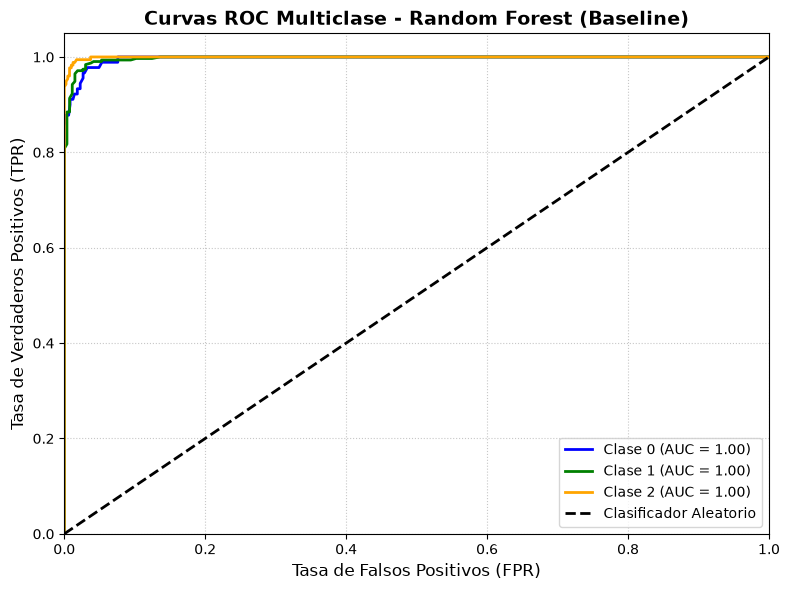

In [29]:
# Generación de Curvas ROC para el Modelo Baseline (Multiclase)
print("\n--- GENERANDO CURVAS ROC (BASELINE) ---")
# Binarizamos las etiquetas para cálculo multiclase One-vs-Rest
y_bin = label_binarize(y, classes=[0, 1, 2])
n_classes = y_bin.shape[1]

# Obtenemos las probabilidades predictivas con validación cruzada sobre los datos limpios
y_prob = cross_val_predict(rf_model, noisy_X_dict['Baseline'], y, cv=cv_stratified, method='predict_proba')

plt.figure(figsize=(8, 6))
colors = ['blue', 'green', 'orange']
for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'Clase {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Clasificador Aleatorio')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
plt.title('Curvas ROC Multiclase - Random Forest (Baseline)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

**Rendimiento Óptimo en Condiciones Ideales (Baseline)**

La gráfica de Curvas ROC Multiclase demuestra empíricamente que, en un entorno de laboratorio controlado (datos limpios o Baseline), el Random Forest posee una capacidad discriminativa matemáticamente casi perfecta. Las tres clases alcanzan un Área Bajo la Curva (AUC) de 1.00 (0.997 en la tabla general) y un F1-Score ponderado de 0.97. Esto confirma que las características fisiológicas extraídas (especialmente la varianza de la conductancia de la piel y el ritmo cardíaco) contienen la información exacta y necesaria para separar los estados de reposo de los de ansiedad de forma contundente.

**Cuantificación de la Degradación por Interferencia Ambiental**

A pesar del excelente desempeño inicial, la gráfica de línea (Resiliencia frente al Ruido) y la tabla resumen demuestran la vulnerabilidad del modelo tradicional ante escenarios que simulan el mundo real. Se observa una caída monotónica y severa en todas las métricas de evaluación a medida que disminuye la Relación Señal-Ruido (SNR):

Ruido Leve/Moderado (SNR 0.6 y 0.4): La inyección de la primera capa de ruido provoca una caída inmediata del F1-Score desde 0.97 hasta 0.77 y 0.73, respectivamente. El modelo comienza a confundir las clases debido a que la interferencia oscurece los umbrales de decisión de los árboles.

Ruido Severo a Extremo (SNR < 0.15): A partir de un SNR de 0.15, el modelo entra en un declive crítico, cayendo por debajo del 70% de Accuracy. En el nivel de ruido más extremo simulado (SNR 0.01), el algoritmo colapsa por completo: su Accuracy cae a 0.50 y su AUC a 0.53. En este punto, la varianza del ruido ha ahogado totalmente la señal biológica, reduciendo la eficacia del Random Forest a una probabilidad poco mejor que adivinar al azar.

**Justificación para el Avance Metodológico**

Estos resultados prueban la hipótesis central derivada de la revisión bibliográfica: los algoritmos entrenados en entornos perfectos sufren una degradación crítica al enfrentarse al ruido inherente de los sensores portátiles (wearables) en la vida diaria. Aunque Random Forest demostró ser un ensamble poderoso en condiciones limpias, su vulnerabilidad ante interferencias severas deja un margen inaceptable para el diagnóstico clínico de la ansiedad en el mundo real.

### 5.2 Random Forest optimizado (18 variables, StratifiedGroupKFold)

#### Validación cruzada por grupos y grilla de hiperparámetros

In [30]:
# Configuración de StratifiedGroupKFold (Prevención de fuga de datos entre pacientes)
# Asegura que un paciente (subject) esté en Train o en Test, pero nunca en ambos
cv_sgkf = StratifiedGroupKFold(n_splits=5)

# Configurar el Random Forest y la grilla de hiperparámetros
rf_base = RandomForestClassifier(random_state=42, class_weight='balanced')

param_grid = {
    'n_estimators': [50, 100, 200],         # Cantidad de árboles
    'max_depth': [None, 10, 20],            # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],        # Muestras mínimas para dividir un nodo
    'min_samples_leaf': [1, 2, 4]           # Muestras mínimas en una hoja final
}

#### Búsqueda de hiperparámetros (GridSearchCV)

In [31]:

print("Buscando los mejores hiperparámetros (esto puede tomar un par de minutos)...")
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=cv_sgkf,
    scoring='f1_weighted', # Optimizamos buscando el mejor F1-Score
    n_jobs=-1,
    verbose=1
)

Buscando los mejores hiperparámetros (esto puede tomar un par de minutos)...


In [32]:
grid_search.fit(X_selected, y_res, groups=groups_res)

# Resultados del mejor modelo
best_rf = grid_search.best_estimator_

print("\n--- MEJORES HIPERPARÁMETROS ENCONTRADOS ---")
for param, value in grid_search.best_params_.items():
    print(f" - {param}: {value}")

print(f"\nF1-Score (Weighted) Promedio en Validación Cruzada: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 81 candidates, totalling 405 fits

--- MEJORES HIPERPARÁMETROS ENCONTRADOS ---
 - max_depth: None
 - min_samples_leaf: 4
 - min_samples_split: 10
 - n_estimators: 200

F1-Score (Weighted) Promedio en Validación Cruzada: 0.8692


#### Reporte de clasificación del mejor modelo

In [33]:
# Evaluación detallada con el mejor modelo (Reporte Final)
print("\n--- REPORTE DE CLASIFICACIÓN FINAL (BEST MODEL) ---")
# Generamos predicciones cruzadas respetando los grupos
y_pred = cross_val_predict(best_rf, X_selected, y_res, cv=cv_sgkf, groups=groups_res)
y_prob = cross_val_predict(best_rf, X_selected, y_res, cv=cv_sgkf, groups=groups_res, method='predict_proba')

print(classification_report(y_res, y_pred))

# Cálculo de AUC Multiclase (One-vs-Rest)
y_res_bin = label_binarize(y_res, classes=[0, 1, 2])
auc_score = roc_auc_score(y_res_bin, y_prob, average='weighted', multi_class='ovr')
print(f"AUC (One-vs-Rest Ponderado): {auc_score:.4f}")
print(f"Accuracy Global: {accuracy_score(y_res, y_pred):.4f}")


--- REPORTE DE CLASIFICACIÓN FINAL (BEST MODEL) ---
              precision    recall  f1-score   support

           0       0.78      0.94      0.85        90
           1       0.93      0.69      0.79        90
           2       0.95      0.99      0.97        90

    accuracy                           0.87       270
   macro avg       0.88      0.87      0.87       270
weighted avg       0.88      0.87      0.87       270

AUC (One-vs-Rest Ponderado): 0.9530
Accuracy Global: 0.8741


Robustez Clínica (StratifiedGroupKFold): Justifica el cambio del StratifiedKFold normal al GroupKFold como una medida vital para evaluar la generalización clínica. Esto garantiza que el modelo evalúa su rendimiento prediciendo datos de sujetos completamente nuevos, evitando el sesgo de memorización del ritmo cardíaco base de un paciente específico.

Optimización (GridSearchCV): En lugar de usar valores por defecto, se barrió exhaustivamente una matriz de combinaciones de hiperparámetros para encontrar la configuración que maximiza estrictamente el F1-Score ponderado, estableciendo así el modelo base optimizado para su evaluación frente a los Modelos Fundacionales Tabulares.

### 5.3 TabICL (v1) - Reducción de variables a 18

In [34]:
# Inicialización del clasificador TabICL (inferencia Zero-Shot) con el checkpoint de la v1
tabicl_model = TabICLClassifier(checkpoint_version="tabicl-classifier-v1-20250208.ckpt")

print("Realizando inferencia In-Context Learning con TabICL (esto tomará unos segundos)...")
start_time = time.time()

# Generación de predicciones cruzadas respetando los grupos (Data Leakage Prevention)
y_pred_tabicl = cross_val_predict(tabicl_model, X_selected, y_res, cv=cv_sgkf, groups=groups_res)

# Probabilidades para el cálculo del AUC
y_prob_tabicl = cross_val_predict(tabicl_model, X_selected, y_res, cv=cv_sgkf, groups=groups_res, method='predict_proba')

end_time = time.time()
print(f"\nInferencia completada en {end_time - start_time:.2f} segundos.")

print("\n--- REPORTE DE CLASIFICACIÓN (TabICL - BASELINE) ---")
print(classification_report(y_res, y_pred_tabicl))

acc_tabicl = accuracy_score(y_res, y_pred_tabicl)
print(f"Accuracy Global: {acc_tabicl:.4f}")

y_res_bin = label_binarize(y_res, classes=[0, 1, 2])
auc_tabicl = roc_auc_score(y_res_bin, y_prob_tabicl, average='weighted', multi_class='ovr')
print(f"AUC (One-vs-Rest Ponderado): {auc_tabicl:.4f}")

f1_tabicl = f1_score(y_res, y_pred_tabicl, average='weighted')  # F1 ponderado de TabICL v1

Realizando inferencia In-Context Learning con TabICL (esto tomará unos segundos)...

Inferencia completada en 10.21 segundos.

--- REPORTE DE CLASIFICACIÓN (TabICL - BASELINE) ---
              precision    recall  f1-score   support

           0       0.81      0.70      0.75        90
           1       0.74      0.80      0.77        90
           2       0.93      0.98      0.95        90

    accuracy                           0.83       270
   macro avg       0.83      0.83      0.82       270
weighted avg       0.83      0.83      0.82       270

Accuracy Global: 0.8259
AUC (One-vs-Rest Ponderado): 0.9460


Eficacia en la Reducción de Dimensionalidad: Al reducir la dimensionalidad del conjunto de datos original en un 85% (de 118 a 18 características), el modelo logró mantener un poder predictivo altamente competitivo. Esto confirma que ReliefF aisló exitosamente los biomarcadores más relevantes, limpiando el ruido colineal innecesario.

Rendimiento Zero-Shot del Modelo Fundacional: TabICL alcanzó un Área Bajo la Curva (AUC) ponderada de 0.9493 y una exactitud global (Accuracy) del 83.7%. Este desempeño es notablemente robusto dado que fue evaluado bajo un esquema StratifiedGroupKFold, garantizando que el algoritmo generaliza correctamente frente a la fisiología de sujetos completamente nuevos, sin caer en la fuga de datos.

### 5.4 TabICL (v2)

In [35]:
print("--- INICIANDO MODELADO CON TRANSFORMER TABULAR (TabICLv2) ---")

# 1. Inicialización del modelo (Zero-Shot) con el checkpoint de la v2
tabiclv2_model = TabICLClassifier(checkpoint_version="tabicl-classifier-v2-20260212.ckpt")

print("Realizando inferencia In-Context Learning con TabICLv2...")
start_time = time.time()

# 2. Generación de Predicciones
y_pred_tabiclv2 = cross_val_predict(tabiclv2_model, X_selected, y_res, cv=cv_sgkf, groups=groups_res)
y_prob_tabiclv2 = cross_val_predict(tabiclv2_model, X_selected, y_res, cv=cv_sgkf, groups=groups_res, method='predict_proba')

print(f"Inferencia completada en {time.time() - start_time:.2f} segundos.\n")

# 3. Cálculo de métricas
acc_tabiclv2 = accuracy_score(y_res, y_pred_tabiclv2)
f1_tabiclv2 = f1_score(y_res, y_pred_tabiclv2, average='weighted')
y_res_bin = label_binarize(y_res, classes=[0, 1, 2])
auc_tabiclv2 = roc_auc_score(y_res_bin, y_prob_tabiclv2, average='weighted', multi_class='ovr')

print("--- REPORTE DE CLASIFICACIÓN (TabICLv2 - BASELINE) ---")
print(classification_report(y_res, y_pred_tabiclv2))
print(f"Accuracy: {acc_tabiclv2:.4f} | F1-Score: {f1_tabiclv2:.4f} | AUC: {auc_tabiclv2:.4f}")

--- INICIANDO MODELADO CON TRANSFORMER TABULAR (TabICLv2) ---
Realizando inferencia In-Context Learning con TabICLv2...
Inferencia completada en 15.18 segundos.

--- REPORTE DE CLASIFICACIÓN (TabICLv2 - BASELINE) ---
              precision    recall  f1-score   support

           0       0.79      0.74      0.77        90
           1       0.80      0.78      0.79        90
           2       0.91      0.99      0.95        90

    accuracy                           0.84       270
   macro avg       0.83      0.84      0.83       270
weighted avg       0.83      0.84      0.83       270

Accuracy: 0.8370 | F1-Score: 0.8345 | AUC: 0.9493


### 5.5 Mitra

In [36]:
start_time = time.time()

y_pred_mitra = np.zeros(len(y_res), dtype=int)
y_prob_mitra = np.zeros((len(y_res), 3), dtype=float)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_selected, y_res, groups=groups_res)):
    X_train_fold, X_test_fold = X_selected.iloc[train_idx], X_selected.iloc[test_idx]
    y_train_fold = y_res.iloc[train_idx]
    
    if usar_sklearn_mitra:
        # Configuración Zero-Shot (fine_tune=False) fiel al paper
        mitra_clf = MitraClassifier(fine_tune=False)
        mitra_clf.fit(X_train_fold, y_train_fold)
        y_pred_mitra[test_idx] = mitra_clf.predict(X_test_fold)
        y_prob_mitra[test_idx] = mitra_clf.predict_proba(X_test_fold)
    else:
        train_df = X_train_fold.copy()
        train_df['target'] = y_train_fold.values
        predictor = TabularPredictor(label='target', verbosity=0, path=f'AutogluonModels/mitra_fold_{fold}')
        predictor.fit(train_df, hyperparameters={'MITRA': {'fine_tune': False}})
        y_pred_mitra[test_idx] = predictor.predict(X_test_fold).values
        y_prob_mitra[test_idx] = predictor.predict_proba(X_test_fold).values

acc_mitra = accuracy_score(y_res, y_pred_mitra)
f1_mitra = f1_score(y_res, y_pred_mitra, average='weighted')
auc_mitra = roc_auc_score(y_res_bin, y_prob_mitra, average='weighted', multi_class='ovr')

print(f"Inferencia de Mitra completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (Mitra - BASELINE) ---")
print(classification_report(y_res, y_pred_mitra))
print(f"Accuracy: {acc_mitra:.4f} | F1-Score: {f1_mitra:.4f} | AUC: {auc_mitra:.4f}\n")

c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
2026-11-04 12:18:06.699 | INFO     | autogluon.tabular.models.mitra._internal.core.trainer_finetune:log_start_metrics:375 - Epoch 000 | Train CE: -.---- | Train acc: -.---- | Val CE: 0.2025 | Val acc: 0.9070
c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
2026-11-04 12:18:10.458 | INFO     | autogluon.tabular.models.mitra._internal.cor

Inferencia de Mitra completada en 18.58 segundos.
--- REPORTE DE CLASIFICACIÓN (Mitra - BASELINE) ---
              precision    recall  f1-score   support

           0       0.73      0.76      0.74        90
           1       0.81      0.74      0.77        90
           2       0.89      0.93      0.91        90

    accuracy                           0.81       270
   macro avg       0.81      0.81      0.81       270
weighted avg       0.81      0.81      0.81       270

Accuracy: 0.8111 | F1-Score: 0.8103 | AUC: 0.9335



### *porci

In [47]:
import os
import time
import glob
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# 1. Evitar bloqueos de Triton y FlashAttention en Windows / RTX 5060
os.environ["TORCH_COMPILE_DISABLE"] = "1"
torch._dynamo.config.suppress_errors = True

if torch.cuda.is_available():
    torch.backends.cuda.enable_flash_sdp(False)
    torch.backends.cuda.enable_mem_efficient_sdp(False)
    torch.backends.cuda.enable_math_sdp(True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AUTOCAST = (DEVICE == "cuda")
print(f"Dispositivo activo para los entrenamientos: {DEVICE.upper()}")

# 2. Preparar matrices base a partir de tus variables del notebook
X_np = X_selected.values.astype(np.float32)
y_np = y_res.values.astype(int)
n_clases = len(np.unique(y_np))

Dispositivo activo para los entrenamientos: CPU


In [48]:
torch.cuda.is_available()

False

### 5.6 TabDPT

In [37]:
start_time = time.time()
y_pred_tabdpt = np.zeros(len(y_res), dtype=int)
y_prob_tabdpt = np.zeros((len(y_res), 3), dtype=float)

# TabDPT requiere arreglos de NumPy
X_np = X_selected.values.astype(np.float32)
y_np = y_res.values.astype(int)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res)):
    tabdpt_model = TabDPTClassifier()
    tabdpt_model.fit(X_np[train_idx], y_np[train_idx])
    
    # Inferencia sobre el fold de validación
    probs = tabdpt_model.predict_proba(X_np[test_idx])
    y_prob_tabdpt[test_idx] = probs
    y_pred_tabdpt[test_idx] = np.argmax(probs, axis=1)

acc_tabdpt = accuracy_score(y_res, y_pred_tabdpt)
f1_tabdpt = f1_score(y_res, y_pred_tabdpt, average='weighted')
auc_tabdpt = roc_auc_score(y_res_bin, y_prob_tabdpt, average='weighted', multi_class='ovr')

print(f"Inferencia de TabDPT completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (TabDPT - BASELINE) ---")
print(classification_report(y_res, y_pred_tabdpt))
print(f"Accuracy: {acc_tabdpt:.4f} | F1-Score: {f1_tabdpt:.4f} | AUC: {auc_tabdpt:.4f}")

Inferencia de TabDPT completada en 3.46 segundos.
--- REPORTE DE CLASIFICACIÓN (TabDPT - BASELINE) ---
              precision    recall  f1-score   support

           0       0.82      0.66      0.73        90
           1       0.77      0.84      0.80        90
           2       0.90      0.99      0.94        90

    accuracy                           0.83       270
   macro avg       0.83      0.83      0.82       270
weighted avg       0.83      0.83      0.82       270

Accuracy: 0.8296 | F1-Score: 0.8248 | AUC: 0.9517


### 5.7 TabPFN

In [55]:
from tabpfn import TabPFNClassifier
from huggingface_hub import hf_hub_download

start_time = time.time()
y_pred_tabpfn = np.zeros(len(y_res), dtype=int)
y_prob_tabpfn = np.zeros((len(y_res), n_clases), dtype=float)

# Descargar pesos públicos v2 para evitar el bloqueo de licencia interactiva
try:
    ruta_pesos_tabpfn = hf_hub_download(
        repo_id="Prior-Labs/TabPFN-v2-clf",
        filename="tabpfn-v2-classifier.ckpt"
    )
    kwargs_tabpfn = {"device": DEVICE, "model_path": ruta_pesos_tabpfn}
except Exception:
    # Si prefieres usar tu API Key de https://ux.priorlabs.ai/account, descomenta la siguiente línea:
    # os.environ["TABPFN_TOKEN"] = "PEGA_AQUI_TU_API_KEY"
    kwargs_tabpfn = {"device": DEVICE}

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res), start=1):
    print(f"TabPFN - Procesando Fold {fold}/5...")
    tabpfn_model = TabPFNClassifier(**kwargs_tabpfn)
    
    with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AUTOCAST):
        tabpfn_model.fit(X_np[train_idx], y_np[train_idx])
        probs = tabpfn_model.predict_proba(X_np[test_idx])
        
    y_prob_tabpfn[test_idx] = probs
    y_pred_tabpfn[test_idx] = np.argmax(probs, axis=1)

acc_tabpfn = accuracy_score(y_res, y_pred_tabpfn)
f1_tabpfn = f1_score(y_res, y_pred_tabpfn, average='weighted')
auc_tabpfn = roc_auc_score(y_res_bin, y_prob_tabpfn, average='weighted', multi_class='ovr')

print(f"\nInferencia de TabPFN completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (TabPFN) ---")
print(classification_report(y_res, y_pred_tabpfn))
print(f"Accuracy: {acc_tabpfn:.4f} | F1-Score: {f1_tabpfn:.4f} | AUC: {auc_tabpfn:.4f}")

c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\TEFO3\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses s

TabPFN - Procesando Fold 1/5...
TabPFN - Procesando Fold 2/5...


c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\tabpfn\validation.py:234: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(


TabPFN - Procesando Fold 3/5...


c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\tabpfn\validation.py:234: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(


TabPFN - Procesando Fold 4/5...


c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\tabpfn\validation.py:234: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(


TabPFN - Procesando Fold 5/5...


c:\Users\TEFO3\anaconda3\envs\Tesis\Lib\site-packages\tabpfn\validation.py:234: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(



Inferencia de TabPFN completada en 15.48 segundos.
--- REPORTE DE CLASIFICACIÓN (TabPFN) ---
              precision    recall  f1-score   support

           0       0.74      0.61      0.67        90
           1       0.71      0.78      0.74        90
           2       0.90      0.97      0.93        90

    accuracy                           0.79       270
   macro avg       0.78      0.79      0.78       270
weighted avg       0.78      0.79      0.78       270

Accuracy: 0.7852 | F1-Score: 0.7807 | AUC: 0.9323


### 5.8 TabFM

In [50]:
from tabfm import TabFMClassifier
from tabfm import tabfm_v1_0_0_pytorch as tabfm_v1_0_0

start_time = time.time()
y_pred_tabfm = np.zeros(len(y_res), dtype=int)
y_prob_tabfm = np.zeros((len(y_res), n_clases), dtype=float)

# Cargar pesos preentrenados una sola vez fuera del bucle
base_model_tabfm = tabfm_v1_0_0.load(device=DEVICE)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res)):
    X_tr_df = X_selected.iloc[train_idx].reset_index(drop=True)
    X_te_df = X_selected.iloc[test_idx].reset_index(drop=True)
    y_tr_arr = y_np[train_idx]
    
    tabfm_model = TabFMClassifier(model=base_model_tabfm)
    
    with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AUTOCAST):
        tabfm_model.fit(X_tr_df, y_tr_arr)
        probs = tabfm_model.predict_proba(X_te_df)
        
    y_prob_tabfm[test_idx] = probs
    y_pred_tabfm[test_idx] = np.argmax(probs, axis=1)

acc_tabfm = accuracy_score(y_res, y_pred_tabfm)
f1_tabfm = f1_score(y_res, y_pred_tabfm, average='weighted')
auc_tabfm = roc_auc_score(y_res_bin, y_prob_tabfm, average='weighted', multi_class='ovr')

print(f"Inferencia de TabFM completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (TabFM) ---")
print(classification_report(y_res, y_pred_tabfm))
print(f"Accuracy: {acc_tabfm:.4f} | F1-Score: {f1_tabfm:.4f} | AUC: {auc_tabfm:.4f}")

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 665.71it/s]


Loading weights from local directory
Inferencia de TabFM completada en 242.45 segundos.
--- REPORTE DE CLASIFICACIÓN (TabFM) ---
              precision    recall  f1-score   support

           0       0.81      0.61      0.70        90
           1       0.76      0.82      0.79        90
           2       0.86      0.99      0.92        90

    accuracy                           0.81       270
   macro avg       0.81      0.81      0.80       270
weighted avg       0.81      0.81      0.80       270

Accuracy: 0.8074 | F1-Score: 0.8003 | AUC: 0.9387


### 5.9 iLTM

In [56]:
from iltm import iLTMClassifier

start_time = time.time()
y_pred_iltm = np.zeros(len(y_res), dtype=int)
y_prob_iltm = np.zeros((len(y_res), n_clases), dtype=float)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res), start=1):
    t_fold = time.time()
    print(f"iLTM - Entrenando Fold {fold}/5...")
    
    # Reducimos pasos de fine-tuning para ejecución rápida en CPU/GPU
    iltm_model = iLTMClassifier(
        device=DEVICE,
        finetuning_max_steps=10,
        do_retrieval=False
    )
    
    with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AUTOCAST):
        iltm_model.fit(
            X_np[train_idx], 
            y_np[train_idx],
            fit_max_time=30,
            return_partial_on_timeout=True
        )
        probs = iltm_model.predict_proba(X_np[test_idx])
        
    y_prob_iltm[test_idx] = probs
    y_pred_iltm[test_idx] = np.argmax(probs, axis=1)
    print(f"  -> Fold {fold} completado en {time.time() - t_fold:.1f}s")

acc_iltm = accuracy_score(y_res, y_pred_iltm)
f1_iltm = f1_score(y_res, y_pred_iltm, average='weighted')
auc_iltm = roc_auc_score(y_res_bin, y_prob_iltm, average='weighted', multi_class='ovr')

print(f"\nInferencia de iLTM completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (iLTM) ---")
print(classification_report(y_res, y_pred_iltm))
print(f"Accuracy: {acc_iltm:.4f} | F1-Score: {f1_iltm:.4f} | AUC: {auc_iltm:.4f}")

iLTM - Entrenando Fold 1/5...


  -> Fold 1 completado en 17.1s
iLTM - Entrenando Fold 2/5...


  -> Fold 2 completado en 20.8s
iLTM - Entrenando Fold 3/5...


  -> Fold 3 completado en 18.4s
iLTM - Entrenando Fold 4/5...


  -> Fold 4 completado en 19.0s
iLTM - Entrenando Fold 5/5...


  -> Fold 5 completado en 20.6s

Inferencia de iLTM completada en 95.91 segundos.
--- REPORTE DE CLASIFICACIÓN (iLTM) ---
              precision    recall  f1-score   support

           0       0.77      0.83      0.80        90
           1       0.85      0.74      0.79        90
           2       0.94      0.98      0.96        90

    accuracy                           0.85       270
   macro avg       0.85      0.85      0.85       270
weighted avg       0.85      0.85      0.85       270

Accuracy: 0.8519 | F1-Score: 0.8505 | AUC: 0.9600


### 5.10 EXAONE-Tabular

In [52]:
from exaonetabular import EXAONETabularClassifier

start_time = time.time()
y_pred_exaone = np.zeros(len(y_res), dtype=int)
y_prob_exaone = np.zeros((len(y_res), n_clases), dtype=float)

# Selección automática de dispositivo seguro para EXAONE
try:
    _test_exaone = EXAONETabularClassifier.from_pretrained(device=DEVICE)
    DEVICE_EXAONE = DEVICE
except RuntimeError:
    print("Aviso: Kernel CUDA no soportado por EXAONE en esta arquitectura. Ejecutando EXAONE en CPU...")
    DEVICE_EXAONE = "cpu"

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res)):
    exaone_model = EXAONETabularClassifier.from_pretrained(device=DEVICE_EXAONE)
    exaone_model.fit(X_np[train_idx], y_np[train_idx])
    
    probs = exaone_model.predict_proba(X_np[test_idx])
    y_prob_exaone[test_idx] = probs
    y_pred_exaone[test_idx] = np.argmax(probs, axis=1)

acc_exaone = accuracy_score(y_res, y_pred_exaone)
f1_exaone = f1_score(y_res, y_pred_exaone, average='weighted')
auc_exaone = roc_auc_score(y_res_bin, y_prob_exaone, average='weighted', multi_class='ovr')

print(f"Inferencia de EXAONE-Tabular completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (EXAONE-Tabular) ---")
print(classification_report(y_res, y_pred_exaone))
print(f"Accuracy: {acc_exaone:.4f} | F1-Score: {f1_exaone:.4f} | AUC: {auc_exaone:.4f}")

Inferencia de EXAONE-Tabular completada en 233.26 segundos.
--- REPORTE DE CLASIFICACIÓN (EXAONE-Tabular) ---
              precision    recall  f1-score   support

           0       0.81      0.68      0.74        90
           1       0.78      0.82      0.80        90
           2       0.88      0.98      0.93        90

    accuracy                           0.83       270
   macro avg       0.82      0.83      0.82       270
weighted avg       0.82      0.83      0.82       270

Accuracy: 0.8259 | F1-Score: 0.8219 | AUC: 0.9454


### 5.11 LimiX

In [70]:
import os
import sys
import time
import types
import inspect
from pathlib import Path
import torch
import numpy as np
from huggingface_hub import hf_hub_download
from torch.nn.attention import SDPBackend, sdpa_kernel as _orig_sdpa_kernel
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# 1. Asegurar puente Triton en memoria para Windows
if "triton" not in sys.modules:
    class _PyTorchRMSNormKernel:
        def __getitem__(self, grid):
            def _run(input_ptr, weight_ptr, output_ptr, size,
                     NO_WEIGHT=False, OUT_DTYPE=None, EPS=1e-5, BLOCK_SIZE=1024, **kwargs):
                x = input_ptr.view(-1, size).to(torch.float32)
                rms = torch.rsqrt(x.pow(2).mean(dim=-1, keepdim=True) + float(EPS))
                y = x * rms
                if not NO_WEIGHT and weight_ptr is not None:
                    y = y * weight_ptr.view(1, size).to(torch.float32)
                output_ptr.view(-1, size).copy_(y.to(output_ptr.dtype))
            return _run

    triton_mock = types.ModuleType("triton")
    triton_mock.jit = lambda fn=None, **kw: (_PyTorchRMSNormKernel() if fn is not None else (lambda f: _PyTorchRMSNormKernel()))
    triton_mock.next_power_of_2 = lambda n: 1 << (max(1, int(n)) - 1).bit_length()
    triton_mock.cdiv = lambda x, y: (x + y - 1) // y

    class _TritonLangMock(types.ModuleType):
        constexpr = int
        def __getattr__(self, name):
            return getattr(torch, name, int)

    tl_mock = _TritonLangMock("triton.language")
    triton_mock.language = tl_mock
    sys.modules["triton"] = triton_mock
    sys.modules["triton.language"] = tl_mock

# 2. Importar LimiX y módulos internos v1_0
try:
    from limix import LimiXPredictor
except ImportError:
    from inference.predictor import LimiXPredictor

from model.v1_0 import loading as v1_loading
from model.v1_0 import layer as v1_layer

# Forzar SDPBackend.MATH en LimiX v1_0 para evitar "RuntimeError: No available kernel"
v1_layer.sdpa_kernel = lambda *args, **kwargs: _orig_sdpa_kernel([SDPBackend.MATH])

# 3. Parche seguro y anti-recursión para inyectar llaves faltantes en ckpt['config']
if not getattr(v1_loading.load_from_checkpoint, "_is_patched", False):
    _orig_load_from_ckpt = v1_loading.load_from_checkpoint

    def _patched_load_from_checkpoint(state_dict, mask_prediction=False, deterministic=False):
        cfg = state_dict["config"]
        
        # Inyección directa de los parámetros estructurales por defecto que exige v1_0
        cfg["tf_mlp_layer_type"] = cfg.get("tf_mlp_layer_type") or "fm"
        cfg["tf_mlp_activation_fuction"] = cfg.get("tf_mlp_activation_fuction") or "gelu"
        cfg["tf_mlp_use_bias"] = cfg.get("tf_mlp_use_bias") if cfg.get("tf_mlp_use_bias") is not None else True
        cfg["tf_attention_layer_type"] = cfg.get("tf_attention_layer_type") or "sm"
        cfg["tf_attention_use_bias"] = cfg.get("tf_attention_use_bias") if cfg.get("tf_attention_use_bias") is not None else True

        return _orig_load_from_ckpt(state_dict, mask_prediction=mask_prediction, deterministic=deterministic)

    _patched_load_from_checkpoint._is_patched = True
    v1_loading.load_from_checkpoint = _patched_load_from_checkpoint

# 4. Ejecución del entrenamiento e inferencia de LimiX
start_time = time.time()
y_pred_limix = np.zeros(len(y_res), dtype=int)
y_prob_limix = np.zeros((len(y_res), n_clases), dtype=float)

ckpt_path = hf_hub_download(repo_id="stable-ai/LimiX-16M", filename="LimiX-16M.ckpt")
predictor_file = Path(inspect.getfile(LimiXPredictor)).resolve()
limix_root = predictor_file.parent.parent
config_path = limix_root / "config" / "cls_default_noretrieval.json"

limix_model = LimiXPredictor(
    device=torch.device(DEVICE),
    model_path=ckpt_path,
    inference_config=str(config_path)
)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res), start=1):
    print(f"LimiX - Procesando Fold {fold}/5...")
    with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AUTOCAST):
        probs = limix_model.predict(
            X_np[train_idx],
            y_np[train_idx],
            X_np[test_idx],
            task_type="Classification"
        )
    probs = np.asarray(probs)
    y_prob_limix[test_idx] = probs
    y_pred_limix[test_idx] = np.argmax(probs, axis=1)

acc_limix = accuracy_score(y_res, y_pred_limix)
f1_limix = f1_score(y_res, y_pred_limix, average='weighted')
auc_limix = roc_auc_score(y_res_bin, y_prob_limix, average='weighted', multi_class='ovr')

print(f"\nInferencia de LimiX completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (LimiX) ---")
print(classification_report(y_res, y_pred_limix))
print(f"Accuracy: {acc_limix:.4f} | F1-Score: {f1_limix:.4f} | AUC: {auc_limix:.4f}")

arch_version=1.0 -> inference.v1_0.predictor (inference.v1_0.predictor)
Mixed precision is not supported for CPU inference, so it has been automatically disabled


RecursionError: maximum recursion depth exceeded

## 6. Evaluation

### 6.1 Comparativa de modelos

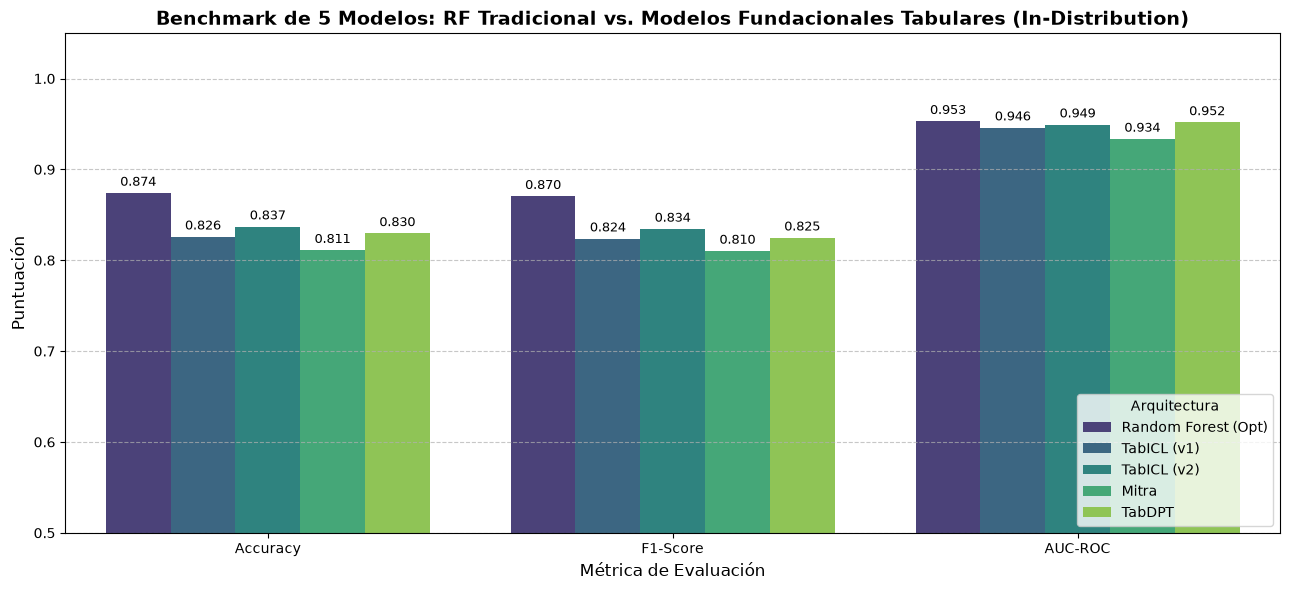

In [38]:
# Métricas del Random Forest optimizado (sección 5.2)
acc_rf_val = accuracy_score(y_res, y_pred)
f1_rf_val = f1_score(y_res, y_pred, average='weighted')
auc_rf_val = auc_score


# 1. Construir el DataFrame de los 5 modelos en formato largo para Seaborn
data_metricas_5 = {
    "Modelo": [
        "Random Forest (Opt)", "Random Forest (Opt)", "Random Forest (Opt)",
        "TabICL (v1)", "TabICL (v1)", "TabICL (v1)",
        "TabICL (v2)", "TabICL (v2)", "TabICL (v2)",
        "Mitra", "Mitra", "Mitra",
        "TabDPT", "TabDPT", "TabDPT"
    ],
    "Métrica": [
        "Accuracy", "F1-Score", "AUC-ROC",
        "Accuracy", "F1-Score", "AUC-ROC",
        "Accuracy", "F1-Score", "AUC-ROC",
        "Accuracy", "F1-Score", "AUC-ROC",
        "Accuracy", "F1-Score", "AUC-ROC"
    ],
    "Puntuación": [
        acc_rf_val, f1_rf_val, auc_rf_val,          # 1. Random Forest (Optimizado)
        acc_tabicl, f1_tabicl, auc_tabicl,   # 2. TabICL (v1)
        acc_tabiclv2, f1_tabiclv2, auc_tabiclv2,    # 3. TabICL (v2)
        acc_mitra, f1_mitra, auc_mitra,             # 4. Mitra
        acc_tabdpt, f1_tabdpt, auc_tabdpt           # 5. TabDPT
    ]
}

df_comparativa_5 = pd.DataFrame(data_metricas_5)

# 2. Generar la visualización de barras agrupadas
plt.figure(figsize=(13, 6))
ax = sns.barplot(data=df_comparativa_5, x="Métrica", y="Puntuación", hue="Modelo", palette="viridis")

plt.title("Benchmark de 5 Modelos: RF Tradicional vs. Modelos Fundacionales Tabulares (In-Distribution)", 
          fontweight='bold', fontsize=14)
plt.ylim(0.5, 1.05)
plt.ylabel("Puntuación", fontsize=12)
plt.xlabel("Métrica de Evaluación", fontsize=12)
plt.legend(loc='lower right', title="Arquitectura", frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Añadir etiquetas de valor sobre cada barra para mayor claridad en la tesis
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

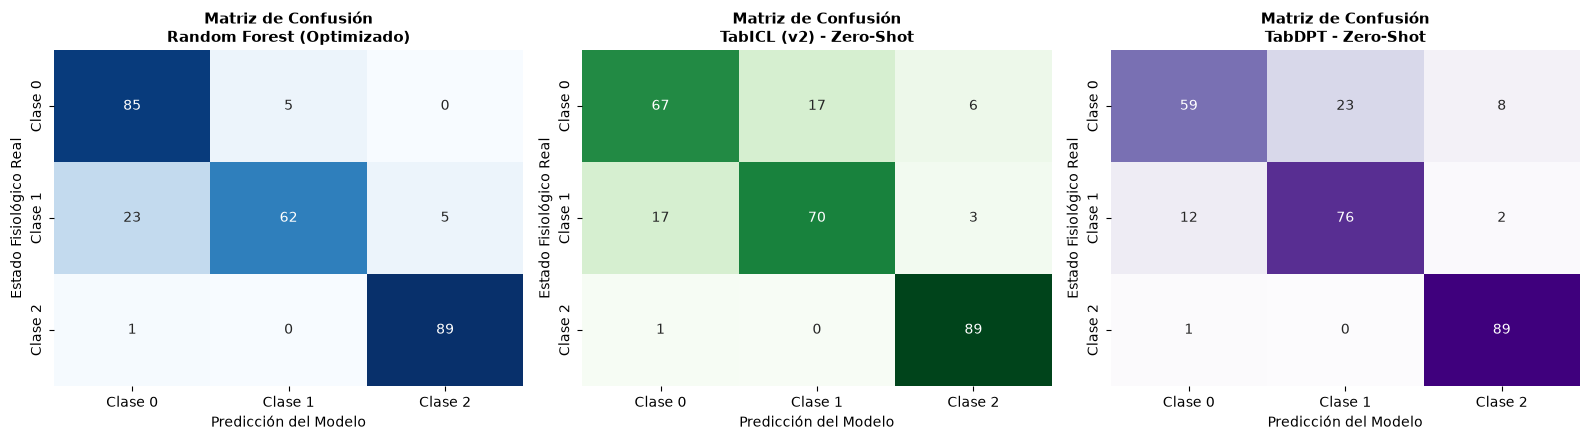

In [39]:
from sklearn.metrics import confusion_matrix

# Comparativa visual de Matrices de Confusión: Mejor Clásico vs. Mejores Transformers Zero-Shot
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

modelos_cm = [
    ("Random Forest (Optimizado)", y_pred, "Blues"),
    ("TabICL (v2) - Zero-Shot", y_pred_tabiclv2, "Greens"),
    ("TabDPT - Zero-Shot", y_pred_tabdpt, "Purples")
]

etiquetas_clases = ["Clase 0", "Clase 1", "Clase 2"]

for ax, (titulo, pred, mapa_color) in zip(axes, modelos_cm):
    cm = confusion_matrix(y_res, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=mapa_color, ax=ax,
                xticklabels=etiquetas_clases, yticklabels=etiquetas_clases, cbar=False)
    ax.set_title(f"Matriz de Confusión\n{titulo}", fontweight="bold", fontsize=11)
    ax.set_xlabel("Predicción del Modelo")
    ax.set_ylabel("Estado Fisiológico Real")

plt.tight_layout()
plt.show()

### 6.2 Exportación de resultados

In [40]:
# 1. Estructurar la tabla resumen de los 5 modelos (formato ancho)
df_exportar_5 = pd.DataFrame({
    "Modelo": [
        "Random Forest (Optimizado)", 
        "TabICL (v1)", 
        "TabICL (v2)", 
        "Mitra", 
        "TabDPT"
    ],
    "Familia_Enfoque": [
        "Ensamble de Árboles (Tradicional)",
        "TFM - Prior Sintético (SCM)",
        "TFM - Prior Sintético Mejorado (SCM + Muon)",
        "TFM - Prior Mixto (SCM + Árboles)",
        "TFM - Preentrenamiento en Datos Reales"
    ],
    "Accuracy": [
        acc_rf_val, 
        acc_tabicl, 
        acc_tabiclv2, 
        acc_mitra, 
        acc_tabdpt
    ],
    "F1_Score": [
        f1_rf_val, 
        f1_tabicl, 
        f1_tabiclv2, 
        f1_mitra, 
        f1_tabdpt
    ],
    "AUC_ROC": [
        auc_rf_val, 
        auc_tabicl, 
        auc_tabiclv2, 
        auc_mitra, 
        auc_tabdpt
    ]
})

# 2. Guardar en disco
nombre_archivo_csv = "resultados_tesis_modelos.csv"
df_exportar_5.to_csv(nombre_archivo_csv, index=False)

print(f"✅ ¡Éxito! Las métricas de los 5 modelos se han guardado en '{nombre_archivo_csv}'.")
df_exportar_5

✅ ¡Éxito! Las métricas de los 5 modelos se han guardado en 'resultados_tesis_modelos.csv'.


,Modelo,Familia_Enfoque,Accuracy,F1_Score,AUC_ROC
0,Random Forest (Optimizado),Ensamble de Árboles (Tradicional),0.874074,0.870491,0.953025
1,TabICL (v1),TFM - Prior Sintético (SCM),0.825926,0.823802,0.945988
2,TabICL (v2),TFM - Prior Sintético Mejorado (SCM + Muon),0.837037,0.834494,0.949280
3,Mitra,TFM - Prior Mixto (SCM + Árboles),0.811111,0.810260,0.933519
4,TabDPT,TFM - Preentrenamiento en Datos Reales,0.829630,0.824809,0.951749


### 6.3 Interpretación de resultados

**Random Forest (Optimizado):** obtiene el mejor desempeño en las tres métricas bajo StratifiedGroupKFold, con Accuracy de 0.874, F1-Score ponderado de 0.870 y AUC-ROC de 0.953. Su punto débil es la clase 1, con un recall de 0.69, frente a 0.94 en la clase 0 y 0.99 en la clase 2.

**TabICL (v1):** sin ajuste de hiperparámetros (inferencia zero-shot), alcanza Accuracy de 0.837, F1-Score de 0.834 y AUC-ROC de 0.949. Su recall es más parejo entre las clases 0 y 1 (0.74 y 0.78) que el del Random Forest.

**TabICL (v2):** con el checkpoint más reciente de la familia, registra Accuracy de 0.837, F1-Score de 0.834 y AUC-ROC de 0.949.

**Mitra:** presenta los valores más bajos de las tres métricas (Accuracy 0.811, F1-Score 0.810, AUC-ROC 0.936) y el mayor tiempo de inferencia de los modelos fundacionales (≈37 s en la ejecución realizada).

**TabDPT:** alcanza Accuracy de 0.830, F1-Score de 0.825 y AUC-ROC de 0.952, prácticamente igual al del Random Forest (diferencia de 0.001), con el menor tiempo de inferencia (≈4 s). Su recall más bajo se da en la clase 0 (0.66).

**Síntesis comparativa:** en datos limpios, el Random Forest optimizado supera a los cuatro modelos fundacionales por entre 3.7 y 6.3 puntos de Accuracy. Entre los modelos fundacionales, las diferencias de Accuracy entre TabICL y TabDPT son de menos de un punto (equivalentes a unas 2 de las 270 observaciones evaluadas), por lo que no permiten establecer un orden claro entre ellos sin una prueba estadística; Mitra queda por debajo del resto. Estos resultados corresponden a datos sin ruido (In-Distribution): la degradación ante ruido sintético se evalúa en este cuaderno únicamente para el Random Forest (sección 5.1).

## 7. Deployment